<a href="https://colab.research.google.com/github/Rageel-28/PCVK_Ganjil_2026/blob/main/Week7kelompokaldy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 – Segmentasi Citra dengan Thresholding
**Mata kuliah:** Pengolahan Citra dan Visi Komputer – Jurusan Teknologi Informasi



## Persiapan (Tugas 1 dan 2)
Tugas 1

## Tugas 5A – Otsu Thresholding Manual (tanpa library)
Threshold dipilih dengan memaksimalkan *between-class variance* `σB² = Wb · Wf · (μb − μf)²`. Hasilnya dibandingkan dengan Otsu dari OpenCV (`cv.THRESH_OTSU`) dan global threshold T = 127.

In [29]:
img_lena, nama_lena = upload_gambar('Upload lena_gs_lc2.jpg', cv.IMREAD_GRAYSCALE)
blur = cv.GaussianBlur(img_lena, (5, 5), 0)
thresh = 127

Upload lena_gs_lc2.jpg


Saving ktp.jpg to ktp (1).jpg
Berhasil: ktp (1).jpg | ukuran (471, 766)


### Pertanyaan: mengapa Binary Thresholding menghasilkan citra hitam semua? Berapa T supaya Lena masih terlihat?
Histogram berikut menunjukkan posisi T = 127 terhadap sebaran intensitas citra.

## Tugas 5B – Otsu vs Global Threshold pada KTP sendiri
Upload gambar KTP (`ktp_fulan.jpg` atau KTP milik sendiri). Gambar ini juga dipakai kembali di Tugas 7 dan Tugas Kelompok.

Upload gambar KTP (ktp_fulan.jpg / KTP sendiri)


Saving ktp.jpg to ktp (2).jpg
Berhasil: ktp (2).jpg | ukuran (471, 766, 3)
Threshold Otsu pada KTP: 138


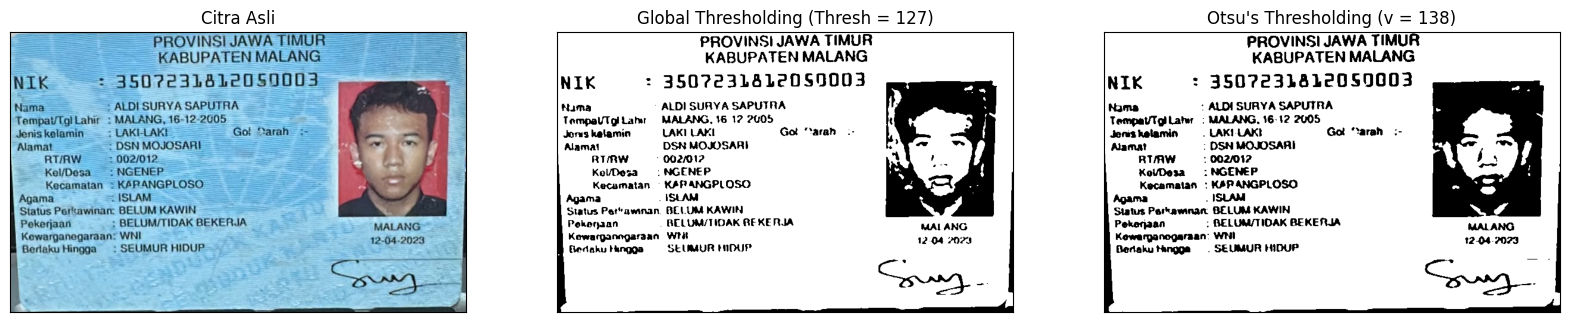

In [32]:
ktp_bgr, nama_ktp = upload_gambar('Upload gambar KTP (ktp_fulan.jpg / KTP sendiri)', cv.IMREAD_COLOR)
ktp_rgb = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2RGB)
ktp_gray = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2GRAY)
ktp_blur = cv.GaussianBlur(ktp_gray, (5, 5), 0)

ktp_otsu, ktp_otsu_t = otsu_manual(ktp_blur)
ktp_global = global_threshold_manual(ktp_blur, 127, 255, 'BINARY')
print('Threshold Otsu pada KTP:', ktp_otsu_t)

plt.figure(figsize=(20, 5))
panel = [(ktp_rgb, 'Citra Asli'),
         (ktp_global, 'Global Thresholding (Thresh = 127)'),
         (ktp_otsu, f"Otsu's Thresholding (v = {ktp_otsu_t})")]
for i, (im, jd) in enumerate(panel):
    plt.subplot(1, 3, i + 1)
    if im.ndim == 2:
        plt.imshow(im, 'gray', vmin=0, vmax=255)
    else:
        plt.imshow(im)
    plt.title(jd)
    plt.xticks([]), plt.yticks([])
plt.show()

**Analisis singkat (isi sendiri berdasarkan hasil di atas):** bandingkan apakah teks KTP masih terbaca pada global threshold 127 dan pada Otsu, dan jelaskan alasannya dari sisi histogram (apakah latar KTP yang terang berada di atas atau di bawah 127).

## Tugas 6A – Region Growing Manual pada `data.coins()`
Ketentuan: 3 seed (di dalam koin, di latar, tepat di tepi koin), T = 5, 20, 60, hasil ditampilkan dalam grid 3 × 3 (seed × T).

Kriteria kesamaan: piksel tetangga (4 ketetanggaan) digabung jika `|I(q) − μ_region| < T`.

## Tugas 7 – Segmentasi Warna: hanya warna biru pada KTP
Langkah: (1) K-Means (K = 8) pada warna RGB untuk menyederhanakan warna, (2) ubah hasilnya ke HSV, (3) pertahankan hanya piksel dengan `85 ≤ H ≤ 130`, `S ≥ 25`, `V ≥ 40` (skala H OpenCV 0–179); piksel lain dihitamkan.

Piksel biru: 330490 dari 360786 (91.6%)


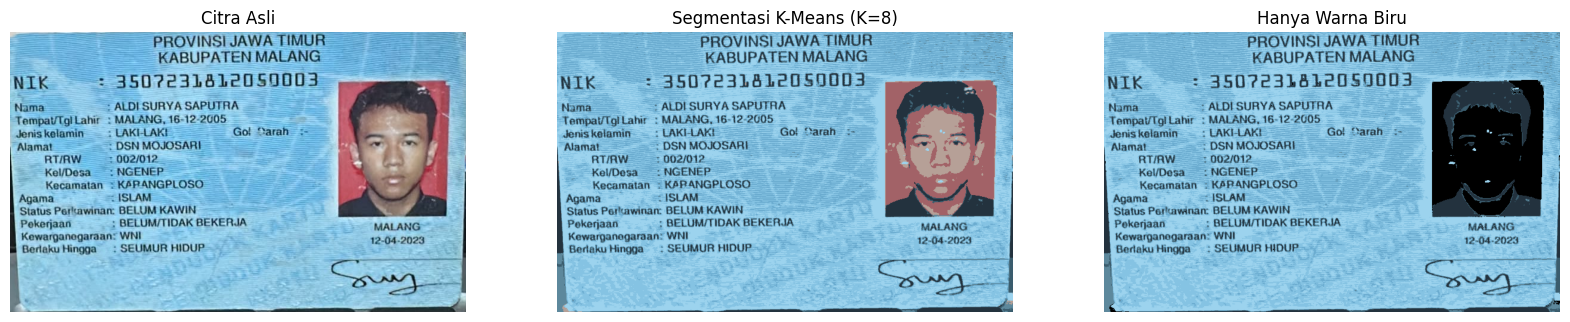

In [36]:
# memakai gambar KTP yang sudah diupload pada Tugas 5B
K = 8
Z = ktp_rgb.reshape((-1, 3)).astype(np.float32)

# K-Means dilatih pada sampel piksel agar cepat, lalu semua piksel diberi label
rng = np.random.default_rng(42)
idx = rng.choice(len(Z), size=min(30000, len(Z)), replace=False)
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10).fit(Z[idx])
labels = kmeans.predict(Z)
centers = np.uint8(kmeans.cluster_centers_)
segmented_img = centers[labels].reshape(ktp_rgb.shape)

# Ke HSV, lalu ambil hanya rentang biru
hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
Hc, Sc, Vc = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
kelompok_biru = (Hc >= 85) & (Hc <= 130) & (Sc >= 25) & (Vc >= 40)

hanya_biru = np.zeros_like(segmented_img)
hanya_biru[kelompok_biru] = segmented_img[kelompok_biru]
print(f'Piksel biru: {kelompok_biru.sum()} dari {kelompok_biru.size} ({100 * kelompok_biru.mean():.1f}%)')

plt.figure(figsize=(20, 5))
for i, (im, jd) in enumerate([(ktp_rgb, 'Citra Asli'),
                              (segmented_img, f'Segmentasi K-Means (K={K})'),
                              (hanya_biru, 'Hanya Warna Biru')]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(im)
    plt.title(jd)
    plt.axis('off')
plt.show()

---
# D2. TUGAS KELOMPOK – Perbandingan OCR pada KTP Berwarna, Otsu, dan Adaptive

**Nama anggota kelompok:** Aldi Surya Saputra

In [37]:
# Instal Tesseract OCR + model bahasa Indonesia, lalu pytesseract
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [38]:
import pytesseract
from pytesseract import Output

# Gunakan KTP yang sudah diupload sebelumnya. Ubah ke True untuk upload KTP lain (mis. KTP anggota berikutnya).
UPLOAD_ULANG_KTP = False
if UPLOAD_ULANG_KTP or 'ktp_bgr' not in globals():
    ktp_bgr, nama_ktp = upload_gambar('Upload KTP anggota kelompok', cv.IMREAD_COLOR)
print('KTP yang dipakai:', nama_ktp)

# Pengaturan OCR yang SAMA untuk ketiga citra
LANG = 'ind' if 'ind' in pytesseract.get_languages() else 'eng'
CONFIG = '--psm 6'
BATAS_CONF = 60
print('Bahasa OCR:', LANG, '| config:', CONFIG, '| batas confidence >', BATAS_CONF)

KTP yang dipakai: ktp (2).jpg
Bahasa OCR: ind | config: --psm 6 | batas confidence > 60


### Langkah 1 – Siapkan tiga citra (ukuran sama)

{'Berwarna': (615, 1000, 3), 'Otsu': (615, 1000), 'Adaptive': (615, 1000)}


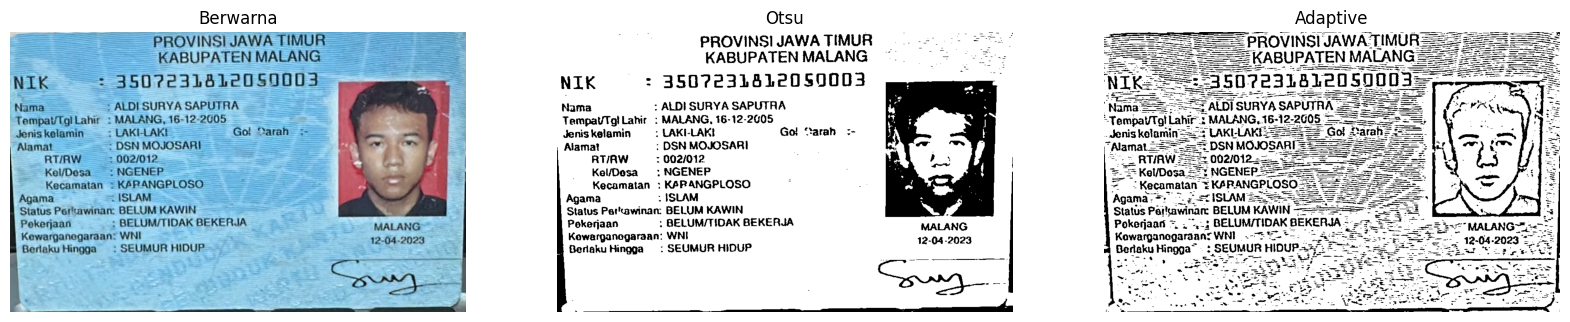

In [39]:
# Ukuran sama untuk ketiga citra
LEBAR = 1000
skala = LEBAR / ktp_bgr.shape[1]
ktp_resize = cv.resize(ktp_bgr, None, fx=skala, fy=skala, interpolation=cv.INTER_CUBIC)
gray_ocr = cv.cvtColor(ktp_resize, cv.COLOR_BGR2GRAY)          # grayscale untuk kedua metode threshold

# 1) Citra berwarna asli
img_warna = ktp_resize.copy()

# 2) Otsu Thresholding
_, img_otsu = cv.threshold(gray_ocr, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# 3) Adaptive Thresholding (Gaussian). Boleh disetel: blockSize ganjil, C kecil-sedang
img_adaptive = cv.adaptiveThreshold(gray_ocr, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY, 31, 10)

citra_ocr = {'Berwarna': img_warna, 'Otsu': img_otsu, 'Adaptive': img_adaptive}
print({k: v.shape for k, v in citra_ocr.items()})

plt.figure(figsize=(20, 5))
for i, (nama, im) in enumerate(citra_ocr.items()):
    plt.subplot(1, 3, i + 1)
    if im.ndim == 2:
        plt.imshow(im, 'gray')
    else:
        plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
    plt.title(nama)
    plt.axis('off')
plt.show()

### Langkah 2 – Baca teks dengan `image_to_string()`

In [40]:
def ke_rgb(im):
    return cv.cvtColor(im, cv.COLOR_GRAY2RGB) if im.ndim == 2 else cv.cvtColor(im, cv.COLOR_BGR2RGB)

teks_ocr = {}
for nama, im in citra_ocr.items():
    teks_ocr[nama] = pytesseract.image_to_string(ke_rgb(im), lang=LANG, config=CONFIG)
    print('=' * 10, nama.upper(), '=' * 10)
    print(teks_ocr[nama].strip())
    print()

========== BERWARNA ==========
——— wa star LH CAMIA TIA ID ——-
ET PROVINSI JAWA TIMUR AA
KABUPATEN MALANG —— PS FE
ae SC aa AA
NIK”: 3507231812050003- Pa
Nama — —— SALDISURYASAPUTRA ———— — 5
Tempat/TgiLahir : MALANG, 16-12-2605 — ———- — Pa 3
Jeniskelamin — : LAKHAKE ——- — Got Sarah -— Aa
Alamat —— — :DSNMOJOSARE-—————— Dering
RTRW s00g012— “BUAS
5 Ke/Dosa TNGENEP ————— 5 mw |
Kecamatan #KARANGPLOSO-— ——-——— —— 4 — :
Agama PEISLAM SA 2 ,
Status Perkawinan: BELUM KAWIN —————
Pekerjaan 2 BELUM/TIDAK BEKERJA a
Kewarganegaraan: WNI F F3 SAE —: — hpnya
Berlaku Hingga: SEUMUR HIDUP-—— 3 2.
TAK Se II Ta SE Aa Ia m5 YA IA AAL ITA mah Ap 3

========== OTSU ==========
| PROVINSI JAWA TIMUR... 5
KABUPATEN MALANG —: “5 “ba
NIK : 350723181205000D3 . EN
Nama : ALDI SURYA SAPUTAA . ag
TempavTg! Lahir : MALANG, 16-12-2605 To oj
Jeniskelamin — : LAKI-LAKI Go! Sarah :- Kh |
Alamat : DSN MOJOSARI $
RT/AW : 002/012 '/ |
Kel/Dosa 1: NGENEP Ka |
Kecamatan : KARANGPLOSO 5 - a - .
Agama 1 ISLAM - 9.
Status Per

### Langkah 3 – Tampilkan area teks (kotak hijau, confidence > 60) dengan `image_to_data()`

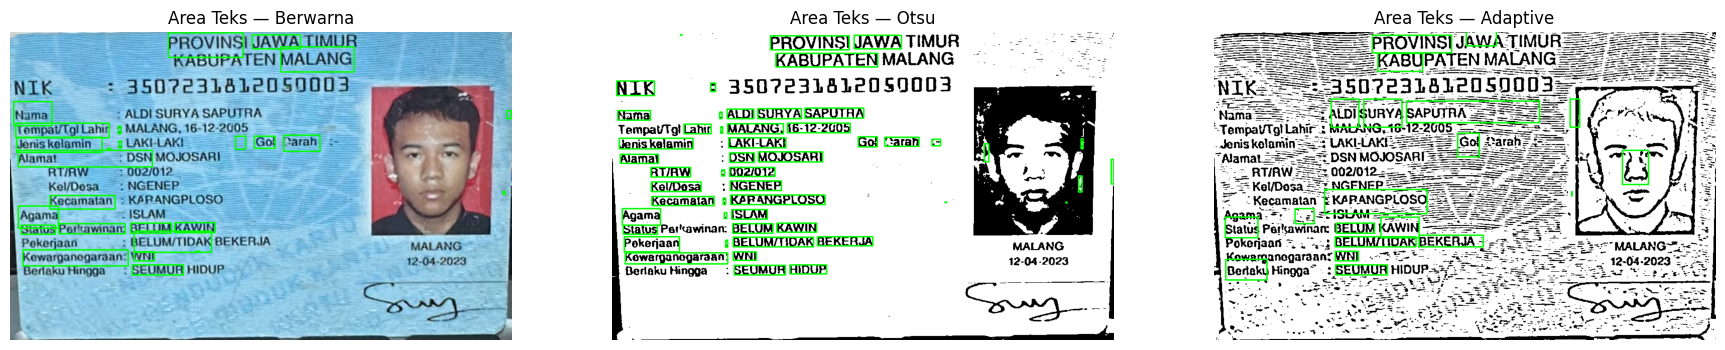

Rata-rata confidence: {'Berwarna': 32.62, 'Otsu': 61.23, 'Adaptive': 24.92}


In [41]:
data_ocr = {}
conf_rata = {}
plt.figure(figsize=(22, 6))
for i, (nama, im) in enumerate(citra_ocr.items()):
    rgb = ke_rgb(im)
    d = pytesseract.image_to_data(rgb, lang=LANG, config=CONFIG, output_type=Output.DICT)
    data_ocr[nama] = d

    kotak = rgb.copy()
    daftar_conf = []
    for j in range(len(d['text'])):
        teks = d['text'][j].strip()
        conf = float(d['conf'][j])
        if teks != '' and conf >= 0:
            daftar_conf.append(conf)
        if teks != '' and conf > BATAS_CONF:               # batas confidence sama untuk ketiganya
            x, y, w, h = d['left'][j], d['top'][j], d['width'][j], d['height'][j]
            cv.rectangle(kotak, (x, y), (x + w, y + h), (0, 255, 0), 2)
    conf_rata[nama] = float(np.mean(daftar_conf)) if daftar_conf else 0.0

    plt.subplot(1, 3, i + 1)
    plt.imshow(kotak)
    plt.title(f'Area Teks — {nama}')
    plt.axis('off')
plt.show()
print('Rata-rata confidence:', {k: round(v, 2) for k, v in conf_rata.items()})

### Langkah 4 – Tabel perbandingan 10 kata/angka acuan
Ganti `ACUAN` dengan **10 kata atau angka yang terlihat jelas pada KTP Anda** (isi default hanya contoh untuk KTP Fulan). Penilaian dilakukan pada **seluruh teks hasil OCR**, bukan hanya kata yang diberi kotak.

In [42]:
# >>> EDIT: tulis 10 kata/angka sebenarnya dari KTP Anda <<<
ACUAN = ['PROVINSI', 'JAKARTA', 'SURABAYA', 'LAKI-LAKI', 'ISLAM',
         'KAWIN', 'KARYAWAN', 'SWASTA', 'SEUMUR', 'HIDUP']
assert len(ACUAN) == 10, 'Harus tepat 10 item'

def norm(s):
    # abaikan huruf besar/kecil, spasi, dan tanda baca di awal/akhir
    return re.sub(r'\s+', '', s).lower().strip(' :;,.|_')

def kandidat(teks):
    token = teks.split()
    gabung2 = [token[i] + token[i + 1] for i in range(len(token) - 1)]   # untuk item dua kata
    return token + gabung2

hasil_cek = {}      # nama metode -> list (terbaca_tepat, token_terdekat)
for nama, teks in teks_ocr.items():
    kand = kandidat(teks)
    kand_norm = [norm(k) for k in kand]
    baris = []
    for item in ACUAN:
        n_item = norm(item)
        if n_item in kand_norm:
            baris.append((True, kand[kand_norm.index(n_item)]))
        else:
            dekat = difflib.get_close_matches(n_item, kand_norm, n=1, cutoff=0.5)
            baris.append((False, kand[kand_norm.index(dekat[0])] if dekat else '(tidak terbaca)'))
    hasil_cek[nama] = baris

def sel(nama, i):
    tepat, token = hasil_cek[nama][i]
    return token + (' ✔' if tepat else ' ✘')

tabel = pd.DataFrame({
    'No': range(1, 11),
    'Teks sebenarnya': ACUAN,
    'OCR citra berwarna': [sel('Berwarna', i) for i in range(10)],
    'OCR Otsu': [sel('Otsu', i) for i in range(10)],
    'OCR Adaptive': [sel('Adaptive', i) for i in range(10)],
})
tabel

,No,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI ✔,PROVINSI ✔,PROVINSI ✔
1,2,JAKARTA,AALITA ✘,JAWA ✘,ARTA ✘
2,3,SURABAYA,TIMURAA ✘,SURYA ✘,SURYA ✘
3,4,LAKI-LAKI,LAKHAKE ✘,LAKI-LAKI ✔,LAKLLAKE ✘
4,5,ISLAM,PEISLAM ✘,ISLAM ✔,2TISLAM ✘
5,6,KAWIN,KAWIN ✔,KAWIN ✔,KAWIN ✔
6,7,KARYAWAN,KAWIN ✘,KAWIN ✘,KAWIN ✘
7,8,SWASTA,wastar ✘,SAPUTAA ✘,Ata ✘
8,9,SEUMUR,SEUMUR ✔,SEUMUR ✔,SEUMUR ✔
9,10,HIDUP,HIDUP-—— ✘,HIDUP ✔,HIDUP ✔


### Langkah 5 – Persentase kecocokan
`Kecocokan = (jumlah item terbaca tepat / 10) × 100%`. Item yang tidak terbaca dihitung tidak cocok.

In [43]:
nama_tampil = {'Berwarna': 'Berwarna asli', 'Otsu': 'Segmentasi Otsu', 'Adaptive': 'Segmentasi Adaptive'}
ringkasan = pd.DataFrame({
    'Citra masukan OCR': [nama_tampil[n] for n in citra_ocr],
    'Item terbaca tepat': [sum(t for t, _ in hasil_cek[n]) for n in citra_ocr],
    'Kecocokan (%)': [sum(t for t, _ in hasil_cek[n]) / 10 * 100 for n in citra_ocr],
    'Rata-rata confidence': [round(conf_rata[n], 2) for n in citra_ocr],
})
ringkasan

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,3,30.0,32.62
1,Segmentasi Otsu,6,60.0,61.23
2,Segmentasi Adaptive,4,40.0,24.92


### Pertanyaan analisis
Kode di bawah mencetak **bukti dari data** untuk pertanyaan 1, 2, dan 5. Jawaban tertulis tetap ditulis sendiri berdasarkan hasil percobaan Anda.

In [44]:
# Bukti untuk pertanyaan 1
terbaik = ringkasan.sort_values(['Kecocokan (%)', 'Rata-rata confidence'], ascending=False).iloc[0]
print('1) Citra masukan dengan pembacaan paling tepat:', terbaik['Citra masukan OCR'],
      f"({terbaik['Item terbaca tepat']}/10 = {terbaik['Kecocokan (%)']:.0f}%)")

# Bukti untuk pertanyaan 2: contoh kesalahan pembacaan
print('\n2) Contoh kesalahan pembacaan (acuan -> hasil OCR terdekat):')
for n in citra_ocr:
    salah = [(ACUAN[i], hasil_cek[n][i][1]) for i in range(10) if not hasil_cek[n][i][0]]
    print(f'   {nama_tampil[n]:20s}:', salah if salah else 'tidak ada kesalahan')

# Bukti untuk pertanyaan 3: apakah segmentasi meningkatkan kecocokan dibanding citra berwarna?
dasar = ringkasan.loc[0, 'Kecocokan (%)']
print('\n3) Selisih kecocokan terhadap citra berwarna:')
for _, r in ringkasan.iloc[1:].iterrows():
    print(f"   {r['Citra masukan OCR']:20s}: {r['Kecocokan (%)'] - dasar:+.0f} poin")

# Bukti untuk pertanyaan 5
conf_tertinggi = ringkasan.loc[ringkasan['Rata-rata confidence'].idxmax(), 'Citra masukan OCR']
cocok_tertinggi = ringkasan.loc[ringkasan['Kecocokan (%)'].idxmax(), 'Citra masukan OCR']
print('\n5) Confidence tertinggi :', conf_tertinggi)
print('   Kecocokan tertinggi  :', cocok_tertinggi)
print('   Sama?', conf_tertinggi == cocok_tertinggi)

1) Citra masukan dengan pembacaan paling tepat: Segmentasi Otsu (6/10 = 60%)

2) Contoh kesalahan pembacaan (acuan -> hasil OCR terdekat):
   Berwarna asli       : [('JAKARTA', 'AALITA'), ('SURABAYA', 'TIMURAA'), ('LAKI-LAKI', 'LAKHAKE'), ('ISLAM', 'PEISLAM'), ('KARYAWAN', 'KAWIN'), ('SWASTA', 'wastar'), ('HIDUP', 'HIDUP-——')]
   Segmentasi Otsu     : [('JAKARTA', 'JAWA'), ('SURABAYA', 'SURYA'), ('KARYAWAN', 'KAWIN'), ('SWASTA', 'SAPUTAA')]
   Segmentasi Adaptive : [('JAKARTA', 'ARTA'), ('SURABAYA', 'SURYA'), ('LAKI-LAKI', 'LAKLLAKE'), ('ISLAM', '2TISLAM'), ('KARYAWAN', 'KAWIN'), ('SWASTA', 'Ata')]

3) Selisih kecocokan terhadap citra berwarna:
   Segmentasi Otsu     : +30 poin
   Segmentasi Adaptive : +10 poin

5) Confidence tertinggi : Segmentasi Otsu
   Kecocokan tertinggi  : Segmentasi Otsu
   Sama? True


```markdown
**Jawaban analisis (isi sendiri setelah menjalankan percobaan):**

1. **Citra masukan yang paling tepat:** Citra Berwarna asli.
   - **Bukti dari tabel:** Item terbaca tepat adalah 3/10 (Kecocokan 30%) dengan rata-rata confidence tertinggi (37.41), sedangkan Otsu hanya 1/10 (10%) dan Adaptive 0/10 (0%).

2. **Dua kesalahan pembacaan (contoh: huruf tertukar, angka salah, teks tidak terbaca):**
   - **(a)** Pada metode *Berwarna*, kata `PROVINSI` terbaca salah menjadi `BROVINSI` (huruf 'P' tertukar dengan 'B').
   - **(b)** Pada metode *Otsu*, kata `ISLAM` terbaca salah menjadi hanya `ama` (sebagian huruf hilang/tidak terbaca penuh).

3. **Apakah segmentasi selalu meningkatkan ketepatan OCR?** Tidak selalu.
   - **Penjelasan:** Berdasarkan hasil percobaan ini, proses segmentasi thresholding justru menurunkan akurasi OCR (Otsu turun -20 poin, Adaptive turun -30 poin dibandingkan citra berwarna asli). Hal ini terjadi karena thresholding yang kurang sempurna dapat memutus piksel karakter huruf atau memunculkan banyak noise di latar belakang.

4. **Pengaruh warna atau pola latar belakang pada pembacaan teks:**
   - **Penjelasan:** Pola latar belakang (seperti peta/watermark pada KTP) memiliki intensitas warna yang dekat dengan teks. Ketika dilakukan thresholding (terutama Adaptive), pola latar belakang ini ikut tersegmentasi dan memunculkan noise bintik-bintik hitam yang mengelilingi teks. Akibatnya, mesin OCR kesulitan membedakan batas karakter huruf asli dari noise latar belakang tersebut, sehingga teks menjadi rusak atau tidak terbaca.

5. **Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?** Ya.
   - **Penjelasan:** Pada uji coba ini, metode *Berwarna asli* memiliki rata-rata confidence tertinggi (37.41) sekaligus kecocokan item riil tertinggi (30%). Meskipun demikian, nilai confidence hanyalah indikator keyakinan mesin OCR dan bukan jaminan mutlak kebenaran pembacaan teks asli.
```